processing data

In [2]:
import os
import cv2
import numpy as np
from sklearn.utils import shuffle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

def load_and_preprocess_data(
    data_dir: str, 
    target_size:tuple = (224, 224) 
    ,validation_extension : tuple = ('.jpeg', '.jpg', '.bmp', '.png')
    ):
    images = []
    labels = []
    
    if not os.path.exists(data_dir):
        raise FileNotFoundError(f"The specified data directory '{data_dir}' does not exist.")
    
    class_names = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
    
    print(f"Found classes: {class_names} , with len : {len(class_names)}")
    
    corruputed_count = 0
    skipped_count = 0
    for label in class_names:
        class_dir = os.path.join(data_dir, label)
        file_list = os.listdir(class_dir)
        
        print(f"Processing class '{label}' with {len(file_list)} files.")
        
        for file_name in file_list:
            img_path = os.path.join(class_dir,file_name)
            ext = os.path.splitext(file_name)[1].lower()
            if ext not in validation_extension:
                try:
                    os.remove(img_path)
                    print(f"Removed file '{img_path}' due to invalid extension '{ext}'.")
                except Exception as e:
                    print(f"Error removing file '{img_path}': {e}")
                skipped_count += 1
                continue
            try:
                img = cv2.imread(img_path)
                
                if img is None:
                    print(f"[CORRUPTED] Could not read image '{img_path}'. Skipping.")
                    corruputed_count += 1
                    os.remove(img_path)
                    continue
                
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, target_size)
                images.append(img)
                labels.append(label)
                
            except Exception as e:
                print(f"[ERROR] An error occurred while processing image '{img_path}': {e}. Skipping.")
                if os.path.exists(img_path):
                    os.remove(img_path)
                skipped_count += 1

    print(f"Preprocessing complete. Corrupted images: {corruputed_count}, Skipped images: {skipped_count}.")
    
    images , labels = shuffle(images, labels, random_state=42)
    images_arr = np.array(images)
    labels_arr = np.array(labels)
    print(f"Final dataset shape: images {images_arr.shape}, labels {labels_arr.shape}")
    return images_arr, labels_arr ,class_names


images_arr, labels_arr, class_names = load_and_preprocess_data("../data/raw")


Found classes: ['glioma', 'meningioma', 'notumor', 'pituitary'] , with len : 4
Processing class 'glioma' with 1621 files.
Processing class 'meningioma' with 1645 files.
Processing class 'notumor' with 2000 files.
Processing class 'pituitary' with 1757 files.
Preprocessing complete. Corrupted images: 0, Skipped images: 0.
Final dataset shape: images (7023, 224, 224, 3), labels (7023,)


Afficher graphiquement le nombre d’images dans chaque classe.

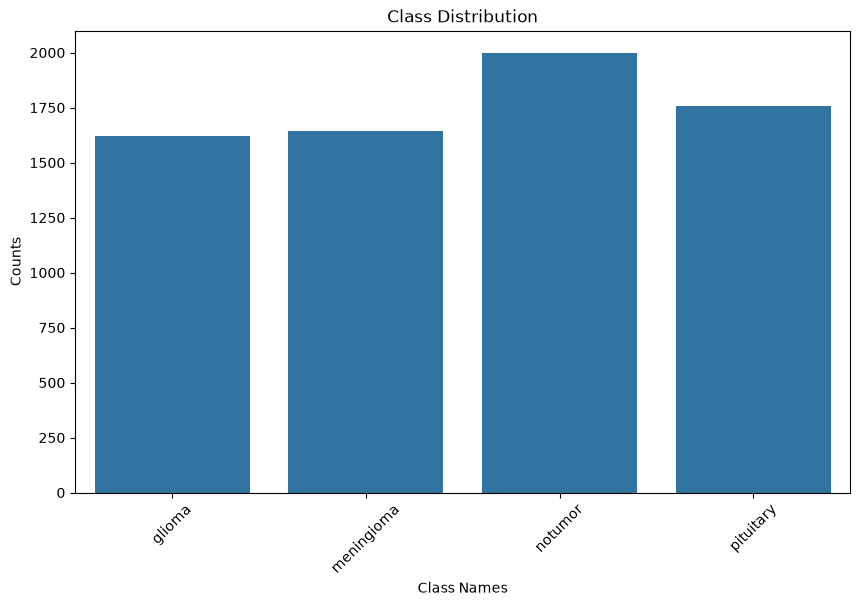

In [3]:
def plot_class_visualization(lavels_arr):
    class_names, counts = np.unique(lavels_arr, return_counts=True)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=class_names, y=counts)
    plt.title("Class Distribution")
    plt.xlabel("Class Names")
    plt.ylabel("Counts")
    plt.xticks(rotation=45)
        
plot_class_visualization(labels_arr)

Montrer un échantillon d’images pour chaque classe.

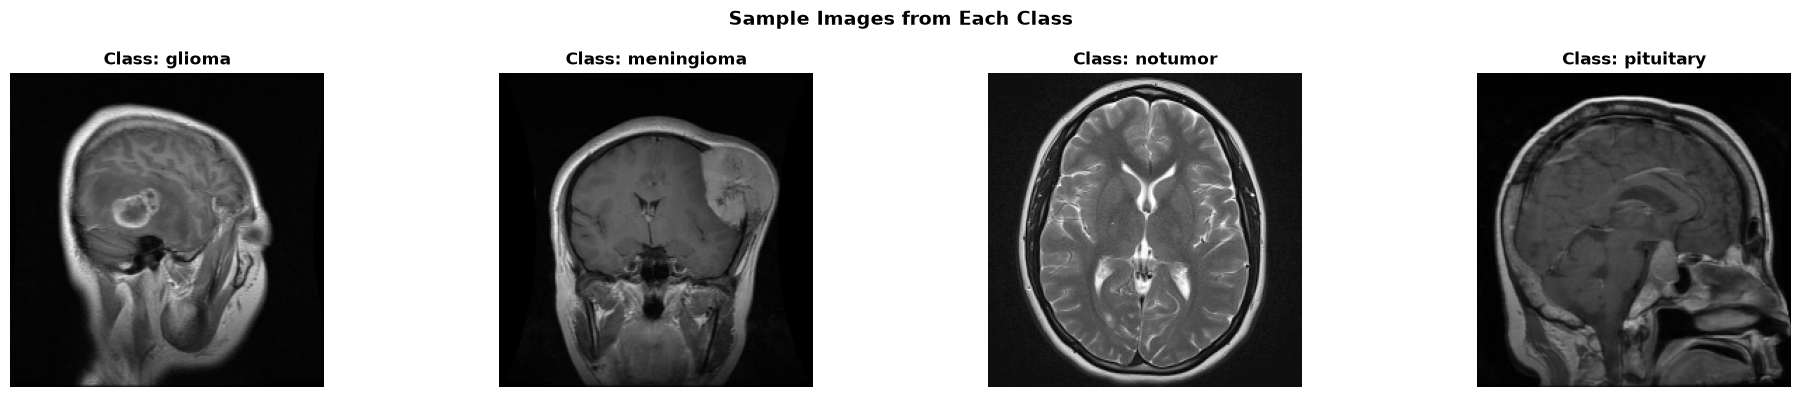

In [4]:
import matplotlib.pyplot as plt
import numpy as np

def display_sample_images(images_arr, labels_arr, class_names):

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    for i, cls in enumerate(class_names):
        indices = np.where(labels_arr == cls)[0]

        sample_index = indices[0]
        axes[i].imshow(images_arr[sample_index])
        axes[i].set_title(f"Class: {cls}", fontsize=12, fontweight='bold')
        axes[i].axis('off')

    plt.suptitle("Sample Images from Each Class", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

display_sample_images(images_arr, labels_arr, class_names)

Vérifier l’équilibre entre les classes et appliquer un rééquilibrage si nécessaire.

In [8]:
def check_class_balance(labels_arr):
    classes, counts = np.unique(labels_arr, return_counts=True)
    total_images = len(labels_arr)
    max_count = np.max(counts)
    min_count = np.min(counts)
    imbalance_ratio = max_count / min_count
    for cls, count in zip(classes, counts):
        percentage = (count / total_images) * 100
        print(f"Class '{cls}': {count} images ({percentage:.2f}%)")
    print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")
    if imbalance_ratio > 1.5:
        print("Warning: Significant class imbalance detected.")
    else:
        print("Class distribution is relatively balanced.")
    
check_class_balance(labels_arr)

Class 'glioma': 1621 images (23.08%)
Class 'meningioma': 1645 images (23.42%)
Class 'notumor': 2000 images (28.48%)
Class 'pituitary': 1757 images (25.02%)
Imbalance ratio (max/min): 1.23
Class distribution is relatively balanced.


Transformer les étiquettes textuelles en format numérique (ex. avec LabelEncoder ou to_categorical).

In [12]:
from sklearn.preprocessing import LabelEncoder

def encoder_labels(labels_arr):
    le = LabelEncoder()
    encoded_labels = le.fit_transform(labels_arr)
    return encoded_labels, le

encoded_labels, label_encoder = encoder_labels(labels_arr)
print("Encoded labels:", encoded_labels)
print("Label encoder:", label_encoder)

Encoded labels: [2 1 1 ... 2 3 0]
Label encoder: LabelEncoder()


Diviser les données en ensembles d’entraînement et de test.

In [ ]:
from sklearn.model_selection import train_test_split
def split_classes(images_arr, y_encoded, test_size=0.2, random_state=42):
    X_train, X_test, y_train, y_test = train_test_split(images_arr, y_encoded, test_size=test_size, random_state=random_state, stratify=y_encoded)
    return X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = split_classes(images_arr, encoded_labels)

Normaliser les valeurs des pixels dans la plage [0, 1].

In [ ]:

print(X_train)
def normalize_pixel_value(X_train, X_test):
    X_train_norm = X_train.astype('float32') / 255.0
    X_test_norm = X_test.astype('float32') / 255.0
    return X_train_norm, X_test_norm

normalized_X_train, normalized_X_test = normalize_pixel_value(X_train, X_test)


[[[[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  ...

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]]


 [[[16 16 16]
   [19 19 19]
   [17 17 17]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[13 13 13]
   [17 17 17]
   [18 18 18]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  [[15 15 15]
   [18 18 18]
   [22 22 22]
   ...
   [ 0  0  0]
   [ 0  0  0]
   [ 0  0  0]]

  ...

  [[17 17 17]
   [14 14 14]
   [14 14 14]
   ...
   [19 19 19]
   [11 11 11]
   [14 14 14]]

  [[23 23 23]
   [17 17 17]
   [12 12 12]
   ...
   [1